# ECG compression with PCA and a learned bottleneck

How does a nonlinear bottleneck compare with PCA at the same latent dimension?

The project reconstructs held-out ECG5000 beats. I compare a linear projection with an autoencoder, report errors in standardized and original amplitude units and inspect several reconstructed signals.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from deep_projects.training import (
    DataSplit,
    Trainer,
    TrainConfig,
    plot_history,
    predict,
    seed_everything,
    split_tensors,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "03_ecg_compression"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## ECG5000 and preprocessing

The course CSV contains one class label followed by 140 signal amplitudes. Labels 1 to 5 are converted to indices 0 to 4. The existing per-beat amplitude scaling is preserved; an additional feature scaler is fitted only on the training subset. There are no patient identifiers in this file, so this split measures beat-level generalization.

torch.Size([5000, 140]) [2919, 1767, 96, 194, 24]


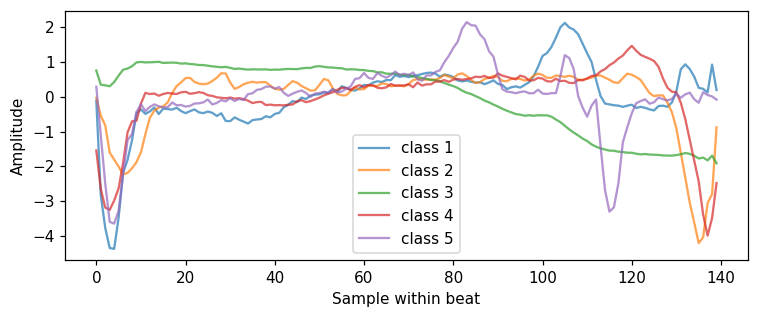

In [5]:
from deep_projects.data import ecg_data
from sklearn.preprocessing import StandardScaler

signals, labels = ecg_data(root / "data" / "ECG5000.csv")
data = split_tensors(signals, labels)
scaler = StandardScaler().fit(data.train.tensors[0].numpy())
standardized = []
for dataset in [data.train, data.validation, data.test]:
    values, targets = dataset.tensors
    standardized.append(
        TensorDataset(
            torch.tensor(scaler.transform(values.numpy()), dtype=torch.float32), targets
        )
    )
data = DataSplit(*standardized)
print(signals.shape, torch.bincount(labels).tolist())
fig, axis = plt.subplots(figsize=(7, 3))
for label in labels.unique():
    example = signals[torch.where(labels == label)[0][0]]
    axis.plot(example.numpy(), label=f"class {int(label) + 1}", alpha=0.7)
axis.set(xlabel="Sample within beat", ylabel="Amplitude")
axis.legend()
fig.tight_layout()
fig.savefig(output / "signals.png", dpi=140)
plt.show()

## Equal latent dimension

PCA finds directions of training variance. The autoencoder learns $\hat{x}=g_\theta(f_\theta(x))$ with a 12-dimensional code. Equal code dimensions do not equate parameter counts, but they make the nominal compression comparison explicit.

class DenseAutoencoder(nn.Module):
    def __init__(self, features=140, latent=12):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(features, 64), nn.ReLU(), nn.Linear(64, latent))
        self.decoder = nn.Sequential(nn.Linear(latent, 64), nn.ReLU(), nn.Linear(64, features))

    def forward(self, signals):
        return self.decoder(self.encoder(signals))



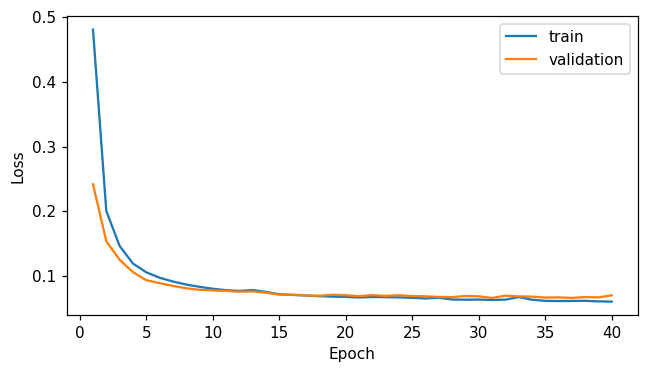

Explained variance: 0.92023027


In [7]:
from sklearn.decomposition import PCA
from deep_projects.models import DenseAutoencoder

print(inspect.getsource(DenseAutoencoder))
latent = 12
pca = PCA(n_components=latent, random_state=1031).fit(data.train.tensors[0].numpy())
reconstruction_data = DataSplit(
    *(
        TensorDataset(dataset.tensors[0], dataset.tensors[0])
        for dataset in [data.train, data.validation, data.test]
    )
)
train_loader, validation_loader, test_loader = reconstruction_data.loaders()
model = DenseAutoencoder(latent=latent)
history = Trainer(model, nn.MSELoss(), TrainConfig(epochs=EPOCHS)).fit(
    train_loader, validation_loader
)
plot_history(history, output / "loss.png")
reconstructed, targets = predict(model, test_loader)
pca_reconstructed = torch.tensor(
    pca.inverse_transform(pca.transform(targets.numpy())), dtype=torch.float32
)
print("Explained variance:", pca.explained_variance_ratio_.sum())

## Error in two units

Standardized errors give each sample position comparable scale. Inverse transformation restores amplitude units. A zero code baseline reconstructs the training feature mean. Reporting it shows how much either model improves beyond an average beat.

In [9]:
rows = []
original_targets = scaler.inverse_transform(targets.numpy())
for name, values in [
    ("training_mean", torch.zeros_like(targets)),
    ("pca", pca_reconstructed),
    ("autoencoder", reconstructed),
]:
    original_values = scaler.inverse_transform(values.numpy())
    rows.append(
        {
            "method": name,
            "standardized_rmse": float(F.mse_loss(values, targets).sqrt()),
            "amplitude_rmse": float(
                np.sqrt(np.mean((original_values - original_targets) ** 2))
            ),
        }
    )
print(pd.DataFrame(rows))
results = {
    "latent_dimensions": latent,
    "nominal_float_ratio": 140 / latent,
    "test": rows,
    "pca_explained_variance": float(pca.explained_variance_ratio_.sum()),
}

          method  standardized_rmse  amplitude_rmse
0  training_mean           0.973487        0.679997
1            pca           0.271020        0.173906
2    autoencoder           0.252789        0.152010


## Waveform inspection

Large peaks and low-amplitude portions can contribute differently to interpretation. The plot retains the sample axis; these files do not supply a per-beat time axis suitable for assigning seconds.

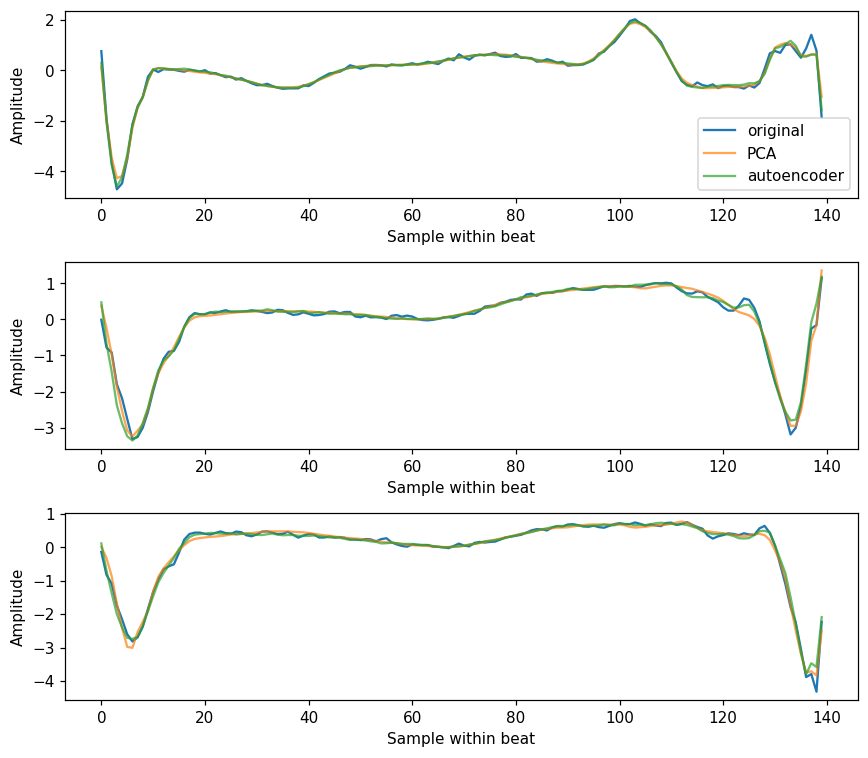

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(8, 7))
for index, axis in enumerate(axes):
    axis.plot(original_targets[index], label="original")
    axis.plot(
        scaler.inverse_transform(pca_reconstructed.numpy())[index],
        label="PCA",
        alpha=0.7,
    )
    axis.plot(
        scaler.inverse_transform(reconstructed.numpy())[index],
        label="autoencoder",
        alpha=0.7,
    )
    axis.set(xlabel="Sample within beat", ylabel="Amplitude")
axes[0].legend()
fig.tight_layout()
fig.savefig(output / "waveforms.png", dpi=140)
plt.show()

## Reading the result

The nominal ratio counts input and latent floats only. A deployable compression scheme would also account for code precision and model storage. Beat-level reconstruction error does not validate clinical preservation of signal features.

In [13]:
result_path = root / "results" / "03_ecg_compression.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/03_ecg_compression.json


## Next experiment

Choose latent dimension on validation RMSE and draw a rate-distortion curve. Add quantization of the latent code and measure the resulting reconstruction change.

## Sources

UniPd Machine Learning for Human Data: uploaded Lab_nn and Labs 1 to 7, plus the [course data folder](https://drive.google.com/drive/folders/14xwb6leBeD3QMZH6wnnIIOi63D1D8xmS). Lab_1 and Lab_7.

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.